# 06 · Test the baseline, unmasked, and masked U-Nets

Compare the original epoch-7 checkpoint with the unmasked and masked ink-weight-15 checkpoints from epoch 12. All three predict the same test examples using the same cached RAFT motion.

**Setup:** Kaggle with Stage 1 data and all three checkpoint sources. Set their paths below. This notebook runs evaluation only.

**Saves:** Test scores, comparison tables and plots, example drawings, animations, and a results ZIP.

In [ ]:
from pathlib import Path

DATASETS = Path("/kaggle/input/datasets/epicfaez")
DATA_ROOT = DATASETS / "interframes-stage1-output" / "interframes_tf_stage1"
ORIGINAL_INPUT = DATASETS / "interframes-stage2-output" / "interframes_tf_stage2"
MASKED_INPUT = Path(
    "/kaggle/working/masking_checkpoints/epoch_012.zip"
)  # Edit for an attached checkpoint or ZIP of checkpoints.
UNMASKED_INPUT = DATASETS / "interframes-stage2-ink15" / "interframes_tf_stage2_ink15"
OUT = Path("/kaggle/working/interframes_test_comparison")
TEMP = Path("/kaggle/temp/interframes_test06")
BATCH_SIZE = 4
THRESHOLD, TOLERANCE = 0.5, 2

## Open the test inputs

Check the Stage 1 identifier and complete test motion cache. Load drawings from the test split.

In [ ]:
import contextlib
import csv
import gc
import hashlib
import json
import math
import os
import shutil
import sqlite3
import sys
import time
import uuid
import warnings
import zipfile
from collections import defaultdict, deque
from concurrent.futures import ThreadPoolExecutor
from functools import lru_cache

os.environ["KERAS_BACKEND"] = "tensorflow"
TEMP.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from IPython.display import display
from PIL import Image
from scipy.ndimage import distance_transform_edt
from tensorflow import keras
from tqdm.auto import tqdm


gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass
tf.config.experimental.enable_tensor_float_32_execution(False)
print("TensorFlow", tf.__version__, "| devices:", gpus or "CPU")


def read_json_file(path):
    return json.loads(Path(path).read_text())


def input_path(path):
    # Kaggle also exposes some attached datasets under /kaggle/input/<slug>.
    path = Path(path)
    legacy = (
        Path("/kaggle/input") / path.relative_to(DATASETS)
        if path.is_relative_to(DATASETS)
        else path
    )
    return legacy if not path.exists() and legacy.exists() else path


DATA_ROOT = input_path(DATA_ROOT)
meta = read_json_file(DATA_ROOT / "stage1_complete.json")
from pathlib import Path

module_dir = DATA_ROOT / "modules"
if str(module_dir) not in sys.path:
    sys.path.insert(0, str(module_dir))
for name in ("data", "learning"):
    loaded = sys.modules.get(name)
    if (
        loaded
        and Path(getattr(loaded, "__file__", "")).resolve()
        != (module_dir / f"{name}.py").resolve()
    ):
        raise RuntimeError(
            f"Restart the runtime to load {name} from the selected Stage 1 archive."
        )
import data as raster
import learning

fingerprint, _ = raster.bundle_fingerprint(DATA_ROOT)
if fingerprint != meta["fingerprint"]:
    raise ValueError("Stage 1 contents differ from its completion marker.")
data_size = int(read_json_file(DATA_ROOT / "config.json")["size"])
manifest = raster.read_records(DATA_ROOT)
splits = {split: [r for r in manifest if r["split"] == split] for split in ("test",)}
del manifest
for split, rows in splits.items():
    n = int(meta["triplets"][split])
    done = np.load(
        DATA_ROOT / "flows" / f"{split}_done.npy", mmap_mode="r", allow_pickle=False
    )
    flow = raster.open_flows(DATA_ROOT, split)
    if (
        not n
        or len(rows) != n
        or len(done) != n
        or not done.all()
        or flow.shape != (n, 2, data_size // 8, data_size // 8, 2)
        or sorted(int(r["cache_index"]) for r in rows) != list(range(n))
    ):
        raise ValueError(f"Manifest and completed motion cache disagree for {split}.")
    print(f"Full {split} split: {n:,} triplets.")

TensorFlow 2.21.0 | devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Full test split: 53,290 triplets.


## Verify all three checkpoints

Check each checkpoint’s dataset, experiment, epoch, model structure, and weight hash. An epoch listed in training history is not a substitute for its saved model file.

In [ ]:
def marker_in_zip(archive, filename):
    matches = [
        n
        for n in archive.namelist()
        if Path(n).name == filename and "_checkpoints" not in Path(n).parts
    ]
    if len(matches) != 1:
        raise ValueError(
            f"ZIP must contain one top-level {filename}; found {matches[:5]}"
        )
    return matches[0]


def bundle_member(relative):
    relative = Path(relative)
    if relative.is_absolute() or ".." in relative.parts:
        raise ValueError("Unexpected path in checkpoint metadata.")
    return relative


class Bundle:
    """Read a Stage 2/4 ZIP or a prepared checkpoint folder through the same interface."""

    def __init__(self, source):
        self.source = Path(source)

    def __enter__(self):
        self.archive = None
        if self.source.is_dir():
            self.root = self.source
        else:
            self.archive = zipfile.ZipFile(self.source)
            try:
                self.root = Path(
                    marker_in_zip(self.archive, "training_state.json")
                ).parent
            except Exception:
                self.archive.close()
                raise
        return self

    def __exit__(self, *args):
        if self.archive is not None:
            self.archive.close()

    def open(self, relative):
        name = self.root / bundle_member(relative)
        return self.archive.open(name.as_posix()) if self.archive else name.open("rb")

    def has(self, relative):
        name = self.root / bundle_member(relative)
        return (
            name.as_posix() in self.archive.NameToInfo
            if self.archive
            else name.is_file()
        )

    def json(self, relative):
        with self.open(relative) as f:
            return json.load(f)

    def copy(self, relative, dest):
        temp = dest.with_name(dest.name + ".part")
        with self.open(relative) as src, temp.open("wb") as out:
            shutil.copyfileobj(src, out, 8 * 1024**2)
        temp.replace(dest)


def atomic_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_name(path.name + ".part")
    with temp.open("w") as f:
        json.dump(value, f, indent=2, allow_nan=False)
        f.flush()
        os.fsync(f.fileno())
    os.replace(temp, path)


def weights_digest(model):
    h = hashlib.sha256()
    for v in model.weights:
        a = np.asarray(v.numpy())
        h.update(str(a.shape).encode())
        h.update(str(a.dtype).encode())
        h.update(a.tobytes())
    return h.hexdigest()


def read_json(path):
    return json.loads(Path(path).read_text())


def saved_policy(path):
    with zipfile.ZipFile(path) as archive:
        layers = json.loads(archive.read("config.json"))["config"]["layers"]
    for layer in layers:
        if layer["config"].get("name") == "interframes_unet":
            layers = layer["config"]["layers"]
            break
    conv = next(
        layer for layer in layers if layer["config"].get("name") == "enc0_conv1"
    )
    dtype = conv["config"]["dtype"]
    return dtype["config"]["name"] if isinstance(dtype, dict) else dtype


def load_network(path, training=True):
    keras.mixed_precision.set_global_policy(saved_policy(path))
    with warnings.catch_warnings(record=True) as notices:
        warnings.simplefilter("always")
        model = keras.models.load_model(path, compile=training)
    for notice in notices:
        if training and "Skipping variable loading for optimizer" in str(
            notice.message
        ):
            raise ValueError(f"Optimizer did not restore completely: {notice.message}")
    return model


def candidates(path, subfolder, epoch):
    if path.is_file():
        yield path
        return
    for root in (path, path / subfolder):
        if (root / "training_state.json").is_file():
            yield root
        for directory in (
            root,
            root / "models_checkpoints",
            root / "masking_checkpoints",
        ):
            yield from sorted(
                directory.glob("*.zip"),
                key=lambda p: (p.name != f"epoch_{epoch:03d}.zip", p.name),
            )
        for commit in sorted(
            (root / "_checkpoints").glob("*/COMMITTED.json"), reverse=True
        ):
            yield commit.parent


def select_checkpoint(label, path, epoch, experiment, subfolder):
    seen = []
    for item in dict.fromkeys(candidates(input_path(path), subfolder, epoch)):
        try:
            if item.is_file():
                with zipfile.ZipFile(item) as z:
                    inner = [
                        p
                        for p in z.namelist()
                        if Path(p).name == f"epoch_{epoch:03d}.zip"
                    ]
                    if len(inner) == 1:
                        target = TEMP / f"{label}_bundle.zip"
                        with z.open(inner[0]) as src, target.open("wb") as dst:
                            shutil.copyfileobj(src, dst)
                        item = target
            with Bundle(item) as b:
                st = b.json("training_state.json")
                cfg = st["run_config"]
                weight = 30 if label == "Original" else 15
                if (
                    st.get("experiment") != experiment
                    or cfg.get("positive_weight") != weight
                    or cfg.get("data_fingerprint") != meta["fingerprint"]
                    or cfg.get("feature_version") != learning.FEATURE_VERSION
                ):
                    continue
                history = st["history"]
                best = (
                    st.get("best_epoch")
                    or min(history, key=lambda h: h["val_loss"])["epoch"]
                )
                seen.append((item.name, st["completed_epochs"], best))
                entry = next((h for h in history if h["epoch"] == epoch), {})
                files = []
                if st["completed_epochs"] == epoch and not st.get("partial"):
                    files.append(("last.keras", entry.get("weights_digest")))
                if best == epoch:
                    files.append(
                        (
                            "best.keras",
                            st.get("best_weights_digest")
                            or entry.get("weights_digest"),
                        )
                    )
                for member, digest in files:
                    if not b.has(member):
                        continue
                    if (
                        not digest
                        and label == "Original"
                        and meta["fingerprint"]
                        == "0a6873b0e80d50f4180bb7bf454d65ee18cb5539436130324cb261f9468e097c"
                    ):
                        digest = "701287bd248ee505f5b440b7b55f0ea3b795abe67113b1d78712e7054d247e12"
                    if not digest:
                        continue
                    local = TEMP / f"{label}.keras"
                    b.copy(member, local)
                    net = load_network(local, training=False)
                    expected = (
                        "interframes_masked_unet"
                        if label == "Masked"
                        else "interframes_unet"
                    )
                    if net.name == expected and weights_digest(net) == digest:
                        print(f"Verified {label} epoch {epoch}: {item} / {member}")
                        return net, dict(
                            epoch=epoch,
                            weights_digest=digest,
                            policy=saved_policy(local),
                        )
        except (OSError, ValueError, KeyError, zipfile.BadZipFile) as err:
            print("Skipping", item, err)
    raise FileNotFoundError(
        f"Missing {label} epoch {epoch} weights at {path}. "
        f"Found (source, last, best): {seen}. Attach a checkpoint containing that epoch."
    )


specs = [
    ("Original", ORIGINAL_INPUT, 7, None, "interframes_tf_stage2"),
    (
        "Unmasked",
        UNMASKED_INPUT,
        13,
        "epoch10_ink30_to_ink15",
        "interframes_tf_stage2_ink15",
    ),
    (
        "Masked",
        MASKED_INPUT,
        12,
        "epoch10_two_warp_masks_ink15_v1",
        "interframes_tf_stage4_masking",
    ),
]
models, identities = {}, {}
for label, path, epoch, experiment, subfolder in specs:
    models[label], identities[label] = select_checkpoint(
        label, path, epoch, experiment, subfolder
    )


Verified Original epoch 7: /kaggle/input/datasets/epicfaez/interframes-stage2-output/interframes_tf_stage2 / best.keras
Verified Unmasked epoch 13: /kaggle/input/datasets/epicfaez/interframes-stage2-ink15/interframes_tf_stage2_ink15 / last.keras
Verified Masked epoch 12: /kaggle/working/masking_checkpoints/epoch_012.zip / last.keras


## Build matching test batches

Reuse the Stage 1 motion files and the batch-loading approach from [notebook 03](03_baseline_colab_resume.ipynb).

In [ ]:
class FastFrames:
    def __init__(self, root, size, ram_gib=8):
        self.root, self.size = Path(root), int(size)
        self.flows = {}
        # Per-entry storage: uint8 image + float32 distance map, plus modest LRU overhead.
        capacity = max(1, int(ram_gib * 1024**3 / (size * size * 5 + 512)))
        self.gray = lru_cache(maxsize=capacity)(self._gray)
        self.distance = lru_cache(maxsize=capacity)(self._distance)
        self.gy, self.gx = np.mgrid[:size, :size].astype(np.float32)

    def _gray(self, relative):
        with Image.open(self.root / relative) as im:
            result = np.asarray(im.convert("L"), dtype=np.uint8).copy()
        if result.shape != (self.size, self.size):
            raise ValueError(f"Unexpected frame size: {relative}: {result.shape}")
        result.setflags(write=False)
        return result

    def ink(self, relative):
        return 1.0 - self.gray(relative).astype(np.float32) / 255.0

    def _distance(self, relative):
        result = raster.distance_map(self.ink(relative))
        result.setflags(write=False)
        return result

    def load_flow(self, split):
        if split not in self.flows:
            print(
                f"Loading existing {split} motion cache into RAM (no RAFT recomputation)...",
                flush=True,
            )
            self.flows[split] = np.array(raster.open_flows(self.root, split), copy=True)

    def splat(self, ink, flow):
        dxpos = self.gx + 0.5 * flow[..., 0]
        dypos = self.gy + 0.5 * flow[..., 1]
        x0, y0 = np.floor(dxpos).astype(np.int64), np.floor(dypos).astype(np.int64)
        dx, dy = dxpos - x0, dypos - y0
        accum = np.zeros(self.size * self.size, np.float32)
        norm = np.zeros_like(accum)
        for ox, oy, weight in [
            (0, 0, (1 - dx) * (1 - dy)),
            (1, 0, dx * (1 - dy)),
            (0, 1, (1 - dx) * dy),
            (1, 1, dx * dy),
        ]:
            x, y = x0 + ox, y0 + oy
            valid = (
                (x >= 0) & (x < self.size) & (y >= 0) & (y < self.size) & (weight > 0)
            )
            indices = y[valid] * self.size + x[valid]
            accum += np.bincount(
                indices, weights=(weight * ink)[valid], minlength=accum.size
            ).astype(np.float32)
            norm += np.bincount(
                indices, weights=weight[valid], minlength=norm.size
            ).astype(np.float32)
        valid = norm > 1e-6
        warped = np.divide(accum, norm, out=np.zeros_like(accum), where=valid)
        return warped.reshape(ink.shape), valid.reshape(ink.shape).astype(np.float32)

    def batch(self, rows):
        x = np.empty((len(rows), self.size, self.size, 8), np.float32)
        y = np.empty((len(rows), self.size, self.size, 1), np.float32)
        for i, row in enumerate(rows):
            a, b = self.ink(row["a"]), self.ink(row["b"])
            flow = self.flows[row["split"]][row["cache_index"]]
            wa, va = self.splat(a, raster.upsample_low(flow[0], self.size))
            wb, vb = self.splat(b, raster.upsample_low(flow[1], self.size))
            x[i] = np.stack(
                [
                    a,
                    b,
                    wa,
                    wb,
                    self.distance(row["a"]),
                    self.distance(row["b"]),
                    va,
                    vb,
                ],
                axis=-1,
            )
            y[i, ..., 0] = self.ink(row["target"])
        return x, y


def batches(frames, rows, batch_size, start=0, workers=2):
    """Bounded threaded prefetch; yields deterministic ordered batches."""
    total = math.ceil(len(rows) / batch_size)
    with ThreadPoolExecutor(max_workers=workers) as pool:
        queue = deque()
        next_index = start
        while next_index < total or queue:
            while next_index < total and len(queue) < max(1, workers):
                chosen = rows[next_index * batch_size : (next_index + 1) * batch_size]
                queue.append((next_index, chosen, pool.submit(frames.batch, chosen)))
                next_index += 1
            index, chosen, future = queue.popleft()
            x, y = future.result()
            yield index, chosen, x, y


try:
    import psutil

    available = psutil.virtual_memory().available
except ImportError:
    available = 6 * 1024**3
try:
    limit = Path("/sys/fs/cgroup/memory.max").read_text().strip()
    if limit.isdigit():
        headroom = int(limit) - int(Path("/sys/fs/cgroup/memory.current").read_text())
        if headroom > 0:
            available = min(available, headroom)
except OSError:
    pass
IMAGE_CACHE_GIB = max(0.25, min(8.0, available * 0.28 / 1024**3))
CPU_WORKERS = max(1, min(4, (os.cpu_count() or 2) // 2))
frame_cache = FastFrames(DATA_ROOT, data_size, IMAGE_CACHE_GIB)
for split in ("test",):
    frame_cache.load_flow(split)
sample = splits["test"][:2]
fast_x, _ = frame_cache.batch(sample)
for index, row in enumerate(sample):
    original = raster.row_features(DATA_ROOT, row, frame_cache.flows["test"])
    np.testing.assert_allclose(fast_x[index], original, rtol=1e-5, atol=2e-6)
print(
    f"Feature parity passed | image cache {IMAGE_CACHE_GIB:.1f} GiB | {CPU_WORKERS} preprocessing workers."
)

Loading existing test motion cache into RAM (no RAFT recomputation)...
Feature parity passed | image cache 7.6 GiB | 2 preprocessing workers.


## Score all three models

Use identical batches and save scores after each batch. All models use ink weight 15 for the evaluation loss, a 0.50 ink cutoff, and a two-pixel line tolerance.

In [ ]:
def score_lines(pred, target, threshold, tolerance):
    p, g = pred >= threshold, target >= threshold
    if p.any() and g.any():
        to_target = distance_transform_edt(~g)[p]
        to_prediction = distance_transform_edt(~p)[g]
        precision = float(np.mean(to_target <= tolerance))
        recall = float(np.mean(to_prediction <= tolerance))
        f1 = 2 * precision * recall / max(precision + recall, 1e-8)
        chamfer = (to_target.mean() + to_prediction.mean()) / 2
    else:
        precision = recall = f1 = float(p.any() == g.any())
        chamfer = 0 if f1 else math.hypot(*p.shape)
    return (
        precision,
        recall,
        f1,
        float(chamfer),
        float(np.abs(pred - target).mean()),
        float(p.mean()),
        float(g.mean()),
    )


QUALITY = (
    "precision",
    "recall",
    "line_f1",
    "chamfer_px",
    "mae",
    "ink_fraction",
    "target_ink_fraction",
)


rows = splits["test"]
ids = {r["id"] for r in rows}
if len(ids) != len(rows):
    raise ValueError("Duplicate test triplet ID.")
protocol = dict(
    models=identities,
    data_fingerprint=meta["fingerprint"],
    split="test",
    triplets=len(rows),
    threshold=THRESHOLD,
    tolerance=TOLERANCE,
    common_loss_weight=15,
)
tag = OUT / "protocol.json"
db_path = OUT / "test.sqlite"
if (tag.exists() and read_json(tag) != protocol) or (
    db_path.exists() and not tag.exists()
):
    raise ValueError(
        "Output folder contains a different test protocol. Set OUT to a new folder."
    )
atomic_json(tag, protocol)


def inference(net):
    objective = learning.InkLoss(positive_weight=15)

    @tf.function(reduce_retracing=True)
    def predict(x, y):
        logits = tf.cast(net(x, training=False), tf.float32)
        return tf.sigmoid(logits), objective.call(y, logits)

    return predict


predictors = {name: inference(net) for name, net in models.items()}
with contextlib.closing(sqlite3.connect(db_path)) as db:
    db.execute(
        "CREATE TABLE IF NOT EXISTS scores(model TEXT,id TEXT,sequence TEXT,gap INTEGER,loss REAL,"
        "precision REAL, recall REAL,line_f1 REAL,chamfer_px REAL,mae REAL,ink_fraction REAL,"
        "target_ink_fraction REAL,PRIMARY KEY(model,id))"
    )
    done = {
        k for (k,) in db.execute("SELECT id FROM scores GROUP BY id HAVING COUNT(*)=3")
    }
    if not done <= ids:
        raise ValueError("Unexpected triplet in the score cache.")
    pending = [r for r in rows if r["id"] not in done]
    print(
        f"{len(done):,} triplets already scored for all three models; {len(pending):,} remaining."
    )
    with (
        ThreadPoolExecutor(max_workers=CPU_WORKERS) as pool,
        tqdm(total=len(rows), initial=len(done), unit="triplet") as bar,
    ):
        for _, batch, x, y in batches(
            frame_cache, pending, BATCH_SIZE, workers=CPU_WORKERS
        ):
            records = []
            for name, predict in predictors.items():
                p, losses = predict(x, y)
                p, losses = p.numpy()[..., 0], losses.numpy().reshape(-1)
                if not np.isfinite(p).all() or not np.isfinite(losses).all():
                    raise FloatingPointError(
                        f"Non-finite prediction or loss from {name}"
                    )
                jobs = [
                    pool.submit(score_lines, a, b[..., 0], THRESHOLD, TOLERANCE)
                    for a, b in zip(p, y)
                ]
                records.extend(
                    (
                        name,
                        r["id"],
                        r["sequence"],
                        int(r["gap"]),
                        float(loss),
                        *job.result(),
                    )
                    for r, loss, job in zip(batch, losses, jobs)
                )
            with db:
                db.executemany(
                    "INSERT INTO scores VALUES (?,?,?,?,?,?,?,?,?,?,?,?)", records
                )
            bar.update(len(batch))


53,290 triplets already scored for all three models; 0 remaining.


100%|##########| 53290/53290 [00:00<?, ?triplet/s]

## Summarize the test results

Give each sequence equal weight for line scores. Average pixel error and evaluation loss over examples. Compute the ink ratio from the sequence-averaged predicted and reference ink amounts.

model,epoch,triplets,common_loss_15,ink_mae,line_f1,chamfer_px,ink_ratio,precision,recall
Original,7,53290,0.63330,0.10475,0.79437,1.22355,5.12374,0.69654,0.98119
Unmasked,13,53290,0.61915,0.07575,0.82628,1.17395,3.87892,0.74920,0.94906
Masked,12,53290,0.62235,0.07392,0.82707,1.19406,3.75843,0.75245,0.94595


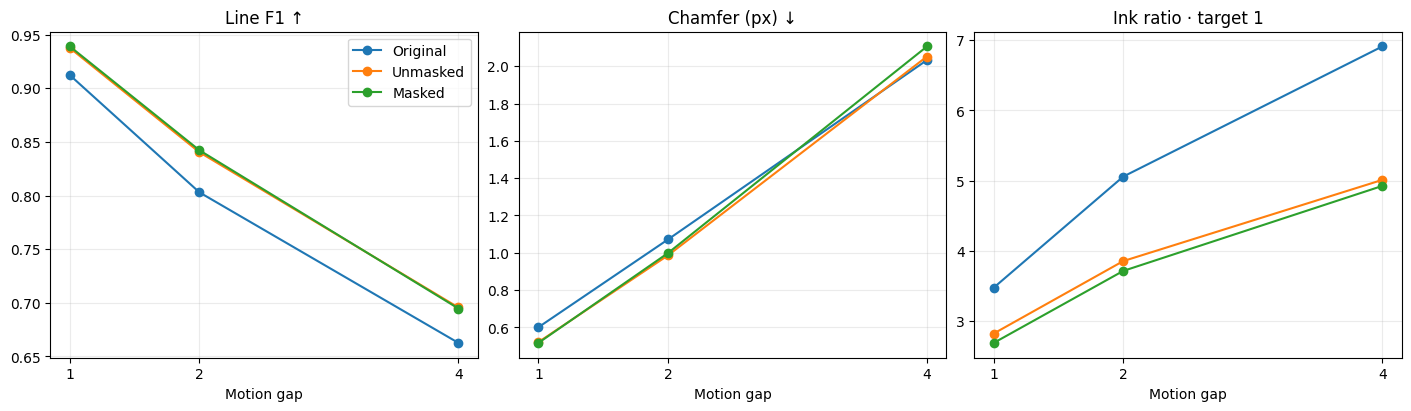

Lowest-F1 triplet IDs for each model: {'Original': ['13333d1cbd074fae0765', '7746103069c032ae47b7', '06049d5e7eeaed89102c', 'a0a0fc0f214c35d62cf4'], 'Unmasked': ['e220a3b12df4e14fc79b', 'b0e195c5ea2110e08c17', '387c27e0261e21d9344d', '06049d5e7eeaed89102c'], 'Masked': ['13333d1cbd074fae0765', 'f3ee630fd947abab1029', 'ee2bcfc1627596c729f6', '06049d5e7eeaed89102c']}


In [ ]:
from IPython.display import HTML
from html import escape


def write_rows(path, records):
    with path.open("w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(records[0]))
        writer.writeheader()
        writer.writerows(records)


def aggregate(db, name, gap=None):
    where, args = (
        ("model=?", [name]) if gap is None else ("model=? AND gap=?", [name, gap])
    )
    count, loss, mae = db.execute(
        f"SELECT COUNT(*), AVG(loss), AVG(mae) FROM scores WHERE {where}", args
    ).fetchone()
    means = ", ".join(f"AVG({k})" for k in QUALITY)
    seq = db.execute(
        f"SELECT {means} FROM scores WHERE {where} GROUP BY sequence", args
    ).fetchall()
    metrics = dict(zip(QUALITY, map(float, np.mean(seq, axis=0))))
    target = metrics["target_ink_fraction"]
    return dict(
        model=name,
        epoch=identities[name]["epoch"],
        triplets=count,
        common_loss_15=loss,
        ink_mae=mae,
        line_f1=metrics["line_f1"],
        chamfer_px=metrics["chamfer_px"],
        ink_ratio=metrics["ink_fraction"] / target if target else None,
        precision=metrics["precision"],
        recall=metrics["recall"],
    )


with contextlib.closing(sqlite3.connect(db_path)) as db:
    overall = [aggregate(db, name) for name in models]
    if any(r["triplets"] != len(rows) for r in overall):
        raise RuntimeError("Finish scoring the full test split first.")
    gaps = sorted({int(r["gap"]) for r in rows})
    by_gap = [dict(gap=g, **aggregate(db, name, g)) for g in gaps for name in models]
    worst = {
        name: [
            k
            for (k,) in db.execute(
                "SELECT id FROM scores WHERE model=? ORDER BY line_f1,id LIMIT 4",
                (name,),
            )
        ]
        for name in models
    }
    result = db.execute("SELECT * FROM scores ORDER BY sequence,id,model")
    with (OUT / "per_triplet.csv").open("w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow([col[0] for col in result.description])
        writer.writerows(result)
write_rows(OUT / "test_comparison.csv", overall)
write_rows(OUT / "by_gap.csv", by_gap)
head = "".join(f"<th>{k}</th>" for k in overall[0])
body = "".join(
    "<tr>"
    + "".join(
        f"<td>{v:.5f}</td>" if isinstance(v, float) else f"<td>{escape(str(v))}</td>"
        for v in r.values()
    )
    + "</tr>"
    for r in overall
)
display(HTML(f"<table><tr>{head}</tr>{body}</table>"))
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for ax, key, title in zip(
    axes,
    ("line_f1", "chamfer_px", "ink_ratio"),
    ("Line F1 ↑", "Chamfer (px) ↓", "Ink ratio · target 1"),
):
    for name in models:
        points = [r for r in by_gap if r["model"] == name]
        ax.plot(gaps, [r[key] for r in points], "o-", label=name)
    ax.set(title=title, xlabel="Motion gap", xticks=gaps)
    ax.grid(alpha=0.25)
axes[0].legend()
fig.savefig(OUT / "test_metrics_by_gap.png", dpi=160)
plt.show()
plt.close(fig)
print("Lowest-F1 triplet IDs for each model:", worst)


## Inspect shared examples and score extremes

Show fixed random cases and the four lowest-F1 cases for each model. The next cell also shows the four highest-F1 cases per model; these selected examples complement the full-set scores.

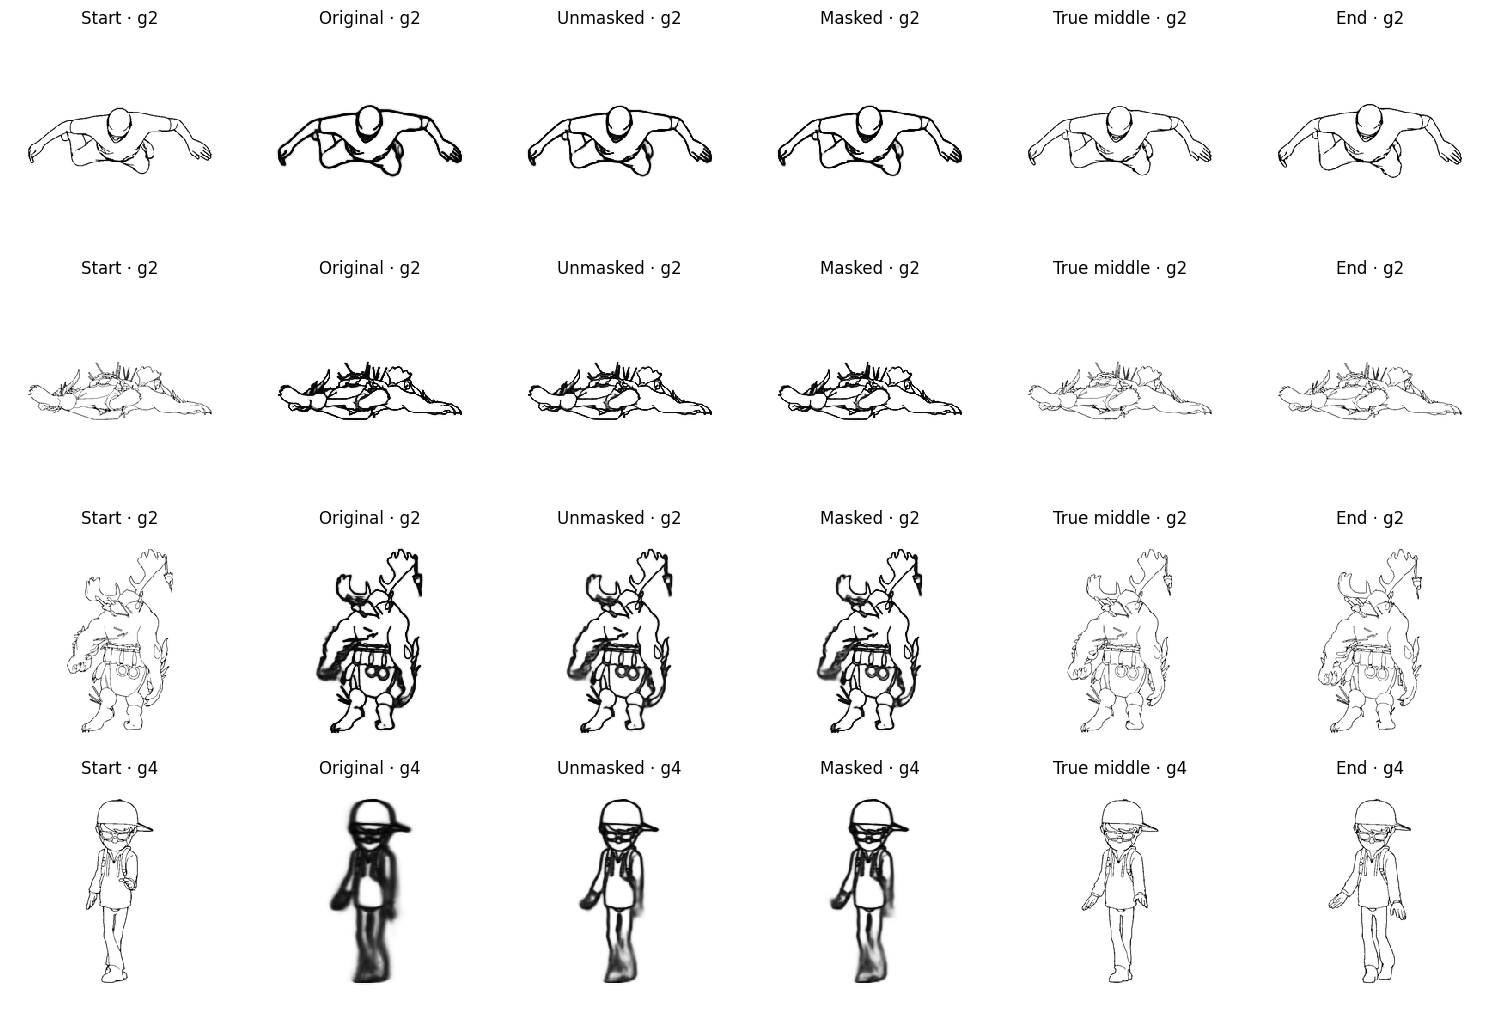

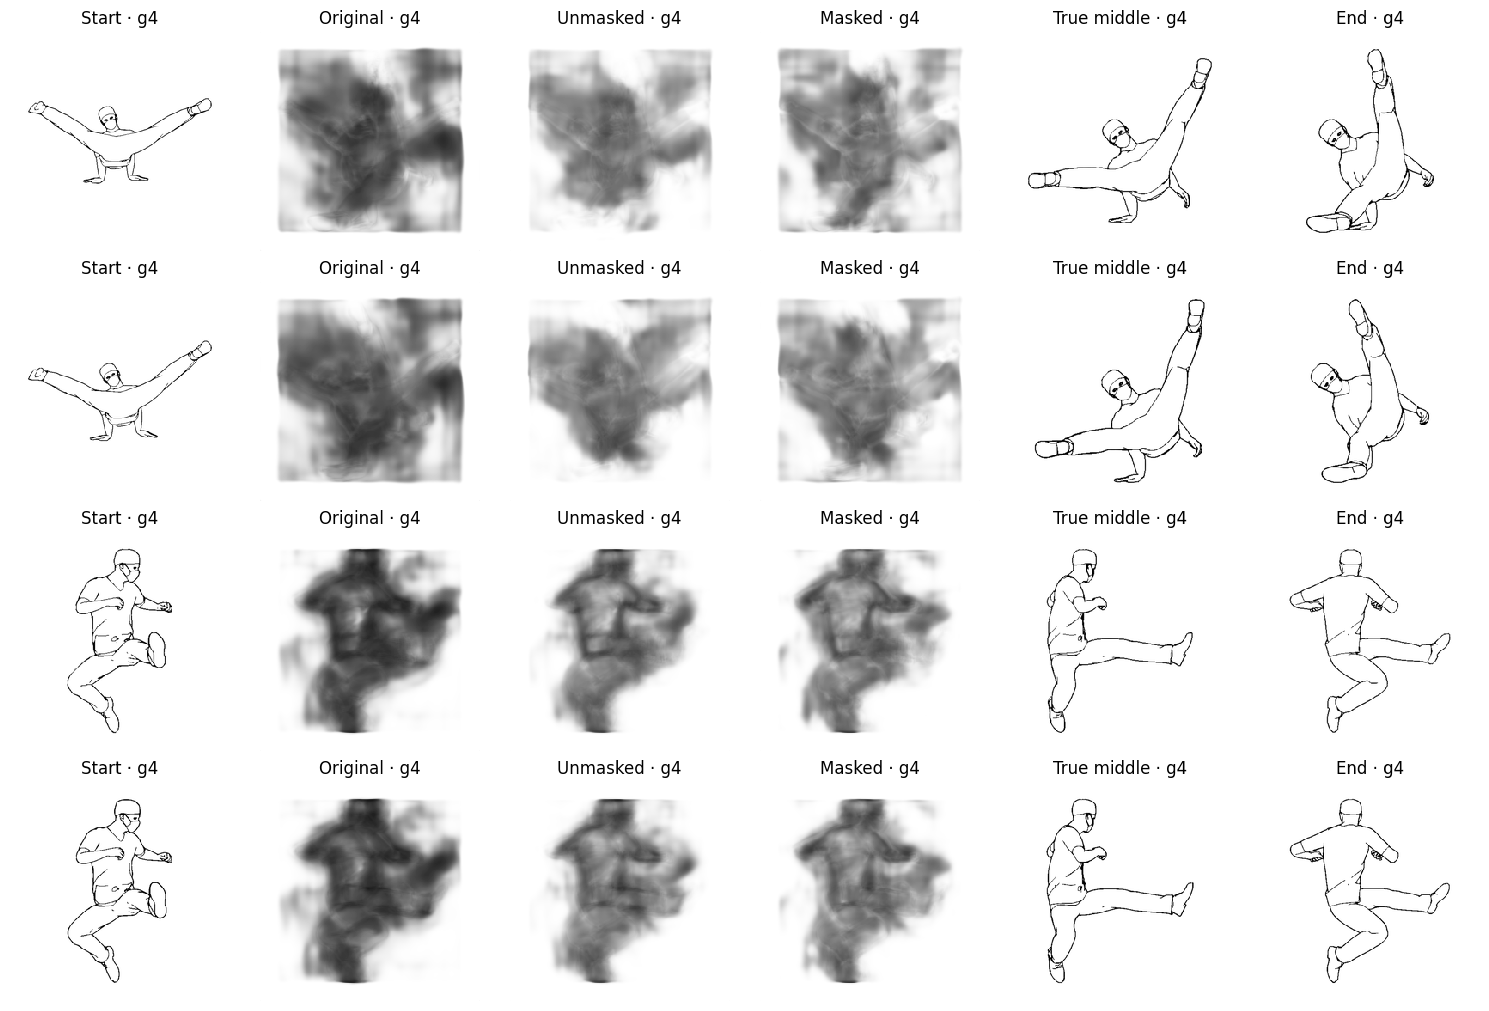

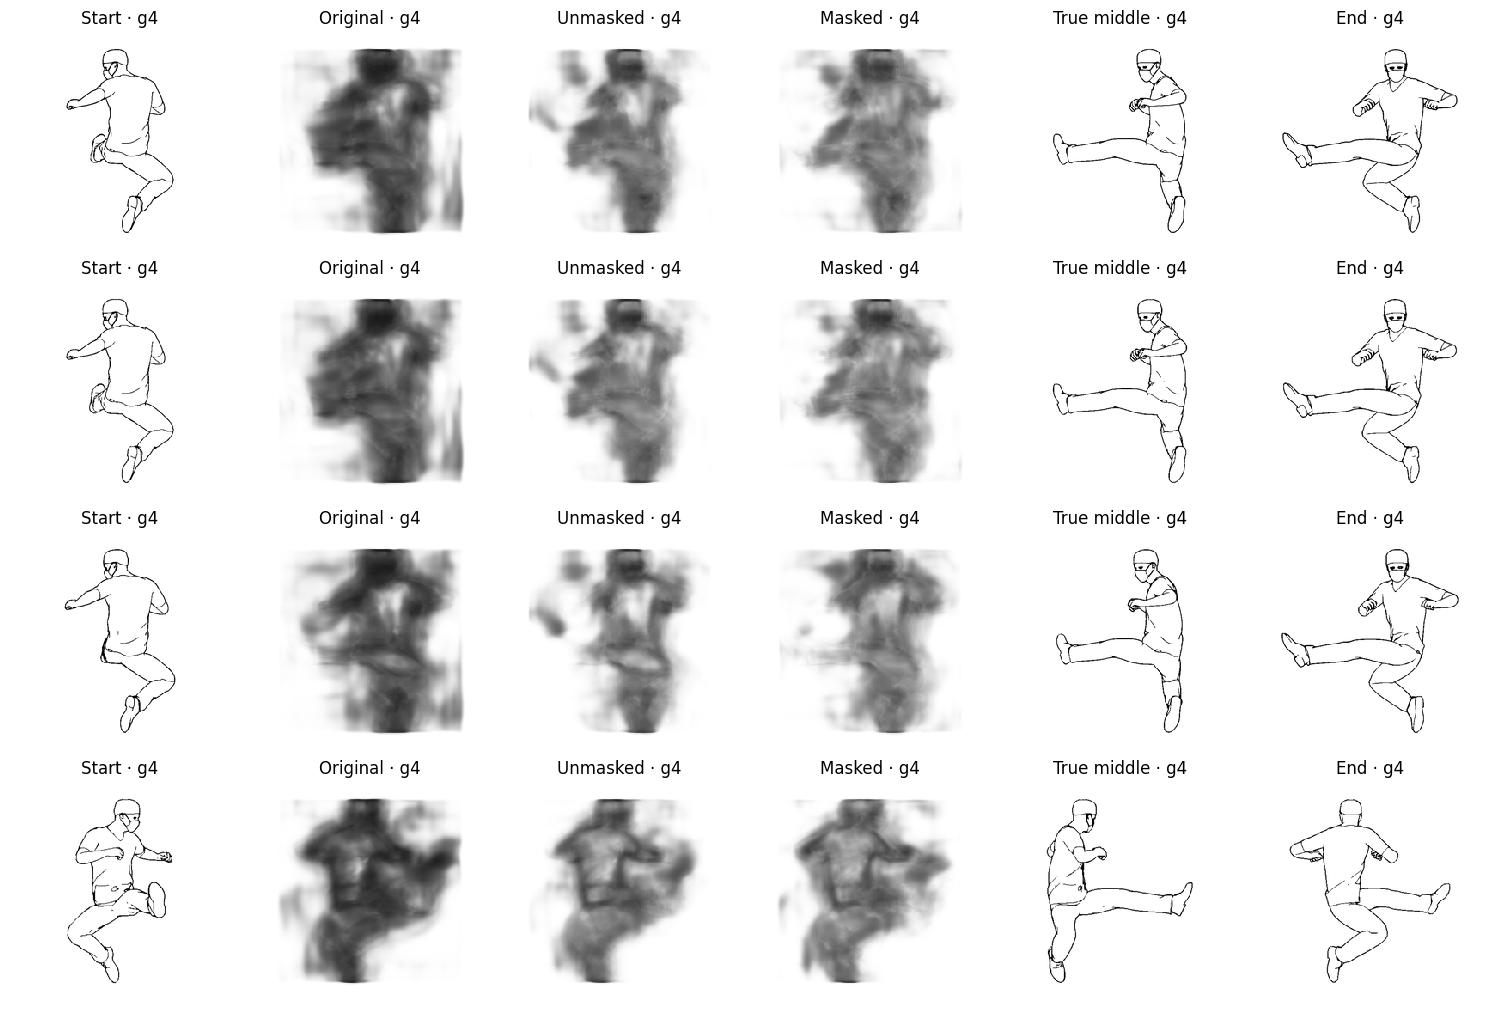

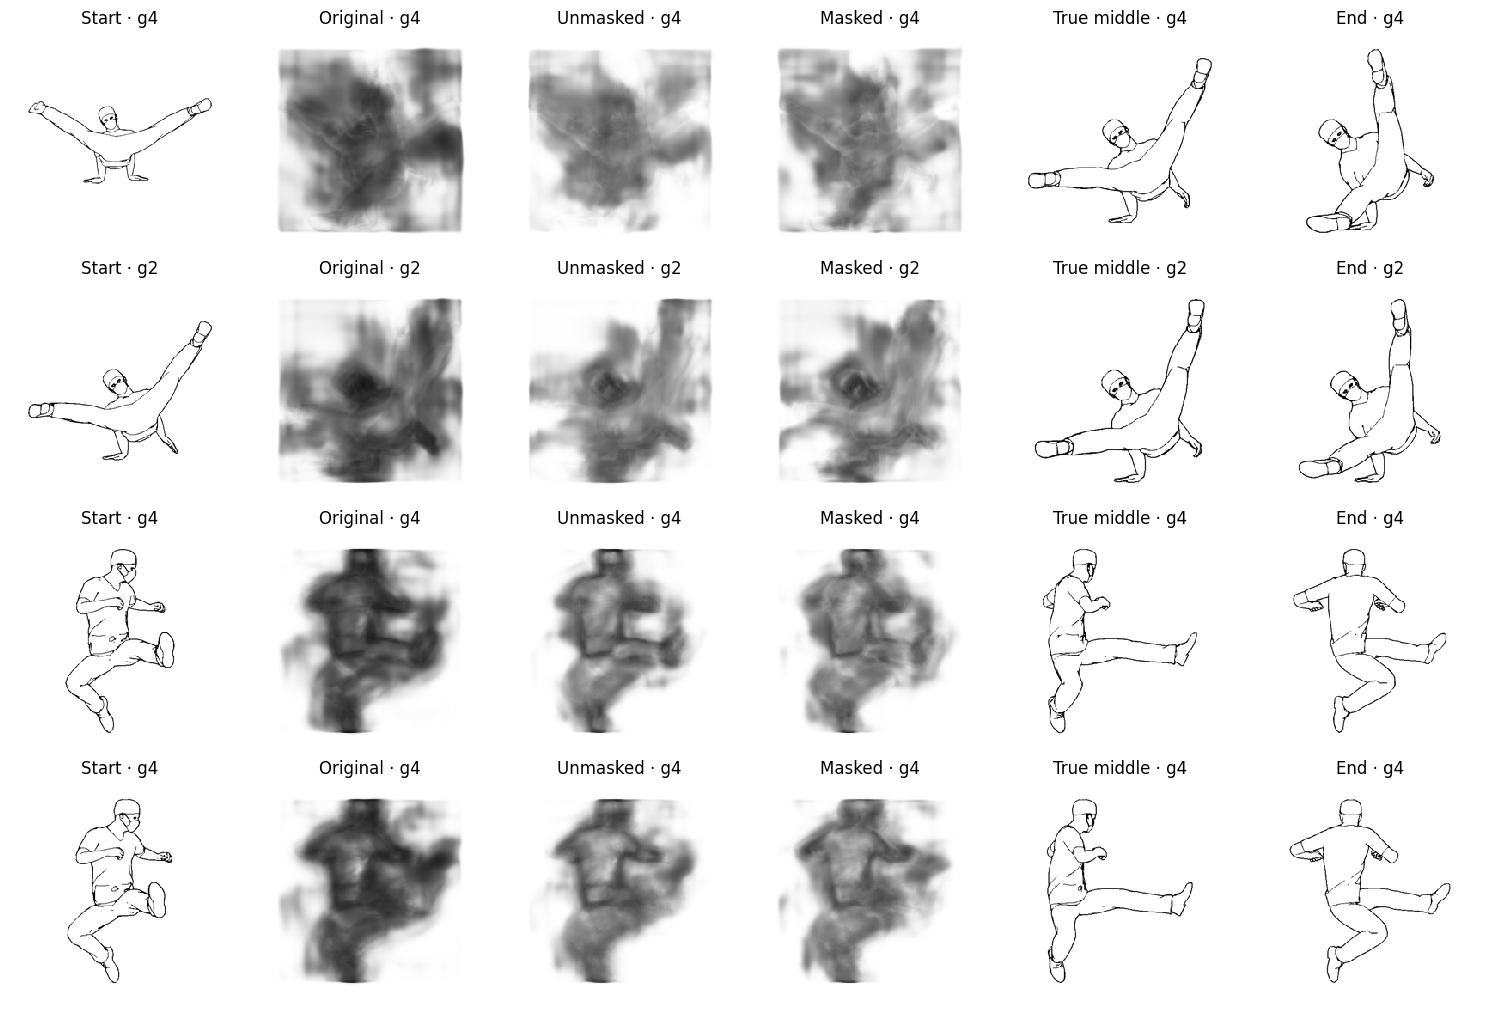

In [ ]:
import random
from PIL import ImageDraw
from IPython.display import Image as GIF, FileLink

lookup = {r["id"]: r for r in rows}


def drawings(row):
    x, y = frame_cache.batch([row])
    predictions = {
        name: tf.sigmoid(net(x, training=False))[0, ..., 0].numpy()
        for name, net in models.items()
    }
    return x[0, ..., 0], x[0, ..., 1], y[0, ..., 0], predictions


def panel(ids, filename):
    fig, axes = plt.subplots(
        len(ids),
        6,
        figsize=(15, 2.5 * len(ids)),
        squeeze=False,
        constrained_layout=True,
    )
    for axes_row, key in zip(axes, ids):
        row = lookup[key]
        a, b, t, p = drawings(row)
        for ax, (label, ink) in zip(
            axes_row, [("Start", a), *p.items(), ("True middle", t), ("End", b)]
        ):
            ax.imshow(ink, cmap="gray_r", vmin=0, vmax=1, interpolation="nearest")
            ax.set_title(f"{label} · g{row['gap']}")
            ax.axis("off")
    fig.savefig(OUT / filename, dpi=125)
    plt.show()
    plt.close(fig)


random_ids = random.Random(42).sample(sorted(lookup), min(4, len(lookup)))
panel(random_ids, "random_examples.png")
for name, keys in worst.items():
    panel(keys, f"lowest_f1_{name}.png")
atomic_json(OUT / "preview_ids.json", dict(random=random_ids, worst=worst))



Best examples for Original (panel rows from top to bottom)
1. 0096eb94a347eac6260f | swimming_jones | gap 1 | F1 1.0000 | Chamfer 0.172 px | ink 1.51×
2. c85b4e5e504c77496a08 | swimming_xbot | gap 1 | F1 1.0000 | Chamfer 0.175 px | ink 1.53×
3. 9bb9f649d6b6df3516af | swimming_jones | gap 1 | F1 1.0000 | Chamfer 0.176 px | ink 1.52×
4. 5d79a1cb2799571eca56 | swimming_xbot | gap 1 | F1 1.0000 | Chamfer 0.176 px | ink 1.54×


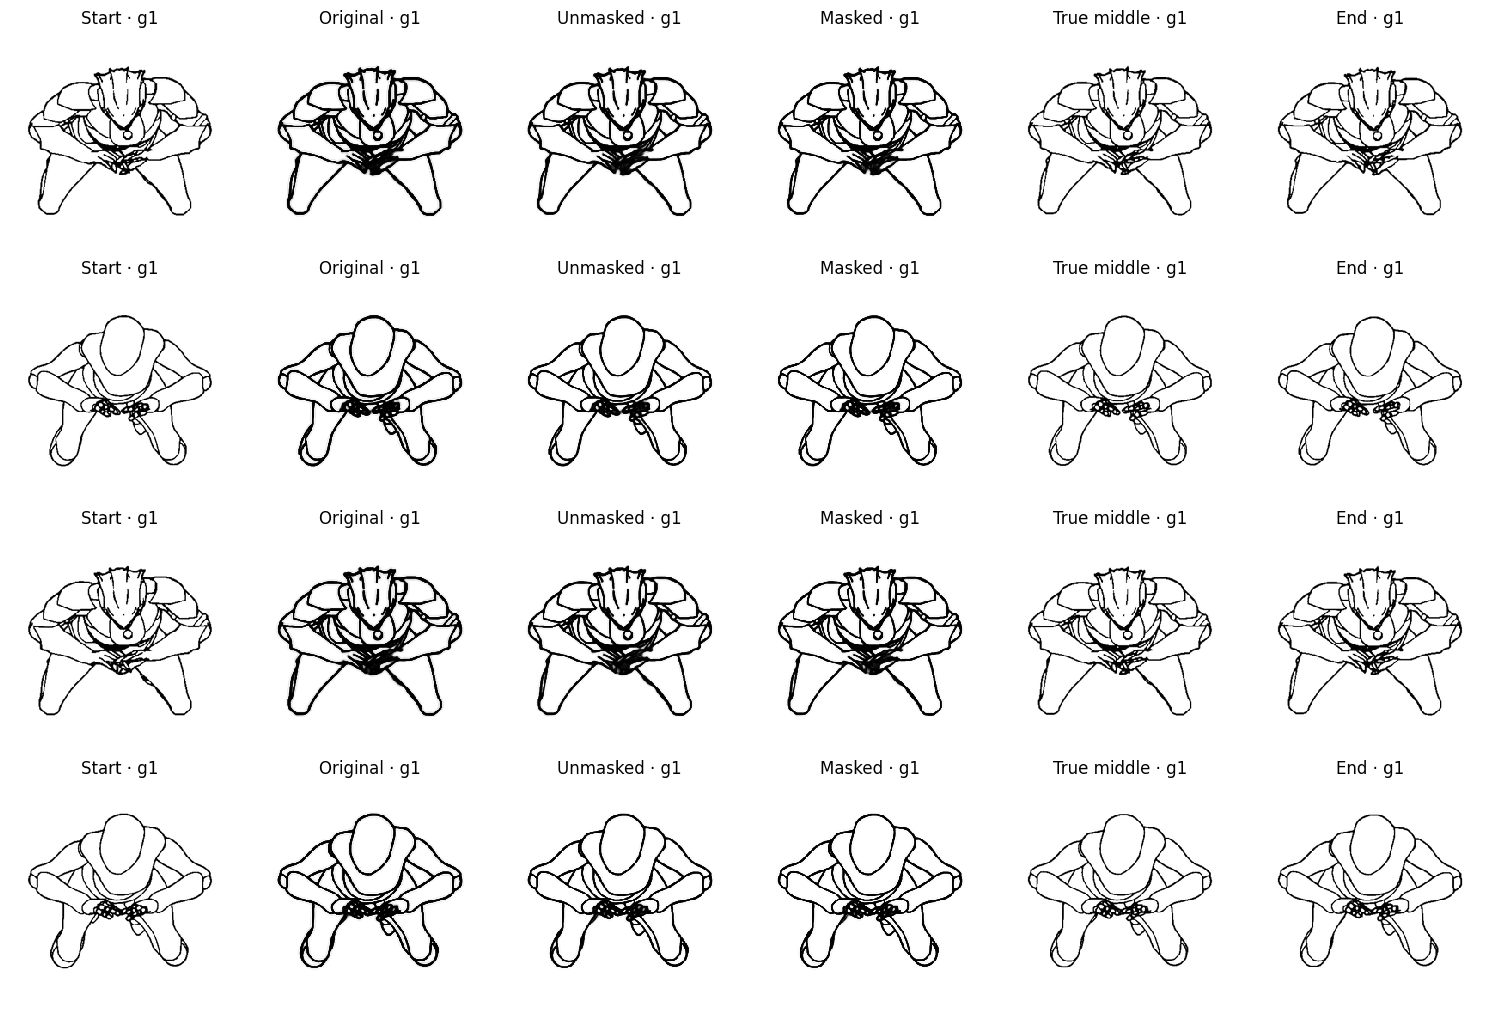


Best examples for Unmasked (panel rows from top to bottom)
1. c85b4e5e504c77496a08 | swimming_xbot | gap 1 | F1 1.0000 | Chamfer 0.151 px | ink 1.43×
2. c35de4bcb763ea2a9bcf | swimming_jones | gap 1 | F1 1.0000 | Chamfer 0.151 px | ink 1.41×
3. 5d79a1cb2799571eca56 | swimming_xbot | gap 1 | F1 1.0000 | Chamfer 0.154 px | ink 1.44×
4. 38670ad83b3a54d70e91 | swimming_jones | gap 1 | F1 1.0000 | Chamfer 0.156 px | ink 1.44×


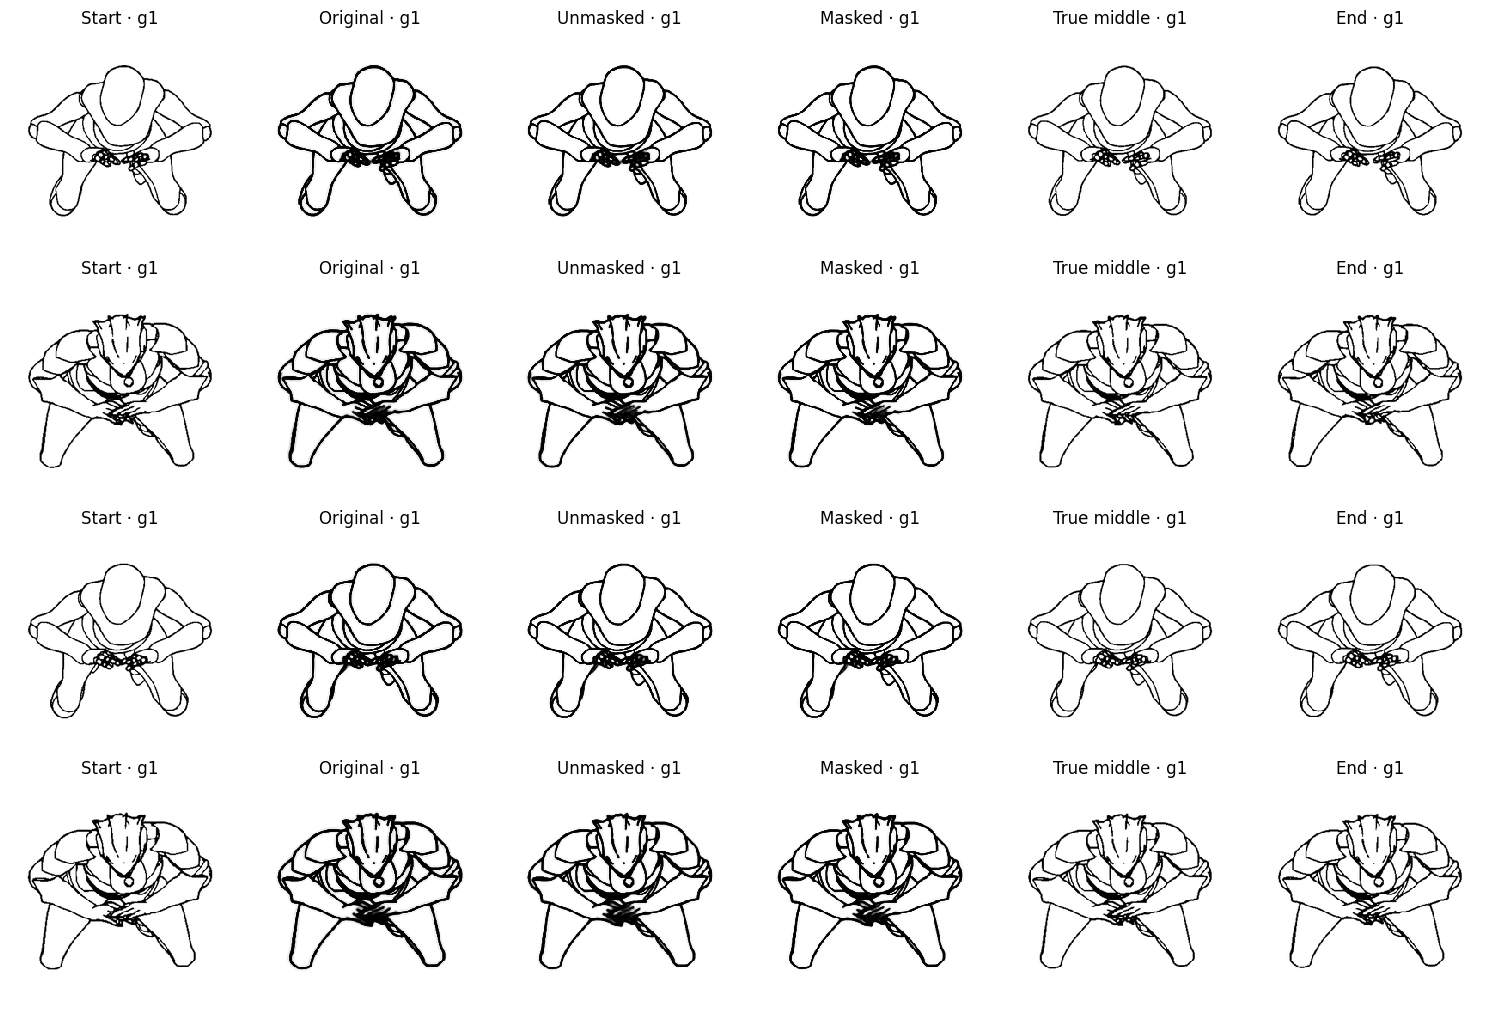


Best examples for Masked (panel rows from top to bottom)
1. c35de4bcb763ea2a9bcf | swimming_jones | gap 1 | F1 1.0000 | Chamfer 0.139 px | ink 1.35×
2. 38670ad83b3a54d70e91 | swimming_jones | gap 1 | F1 1.0000 | Chamfer 0.141 px | ink 1.37×
3. 74a28e89e6aa45489b01 | swimming_aj | gap 1 | F1 1.0000 | Chamfer 0.141 px | ink 1.38×
4. c85b4e5e504c77496a08 | swimming_xbot | gap 1 | F1 1.0000 | Chamfer 0.143 px | ink 1.40×


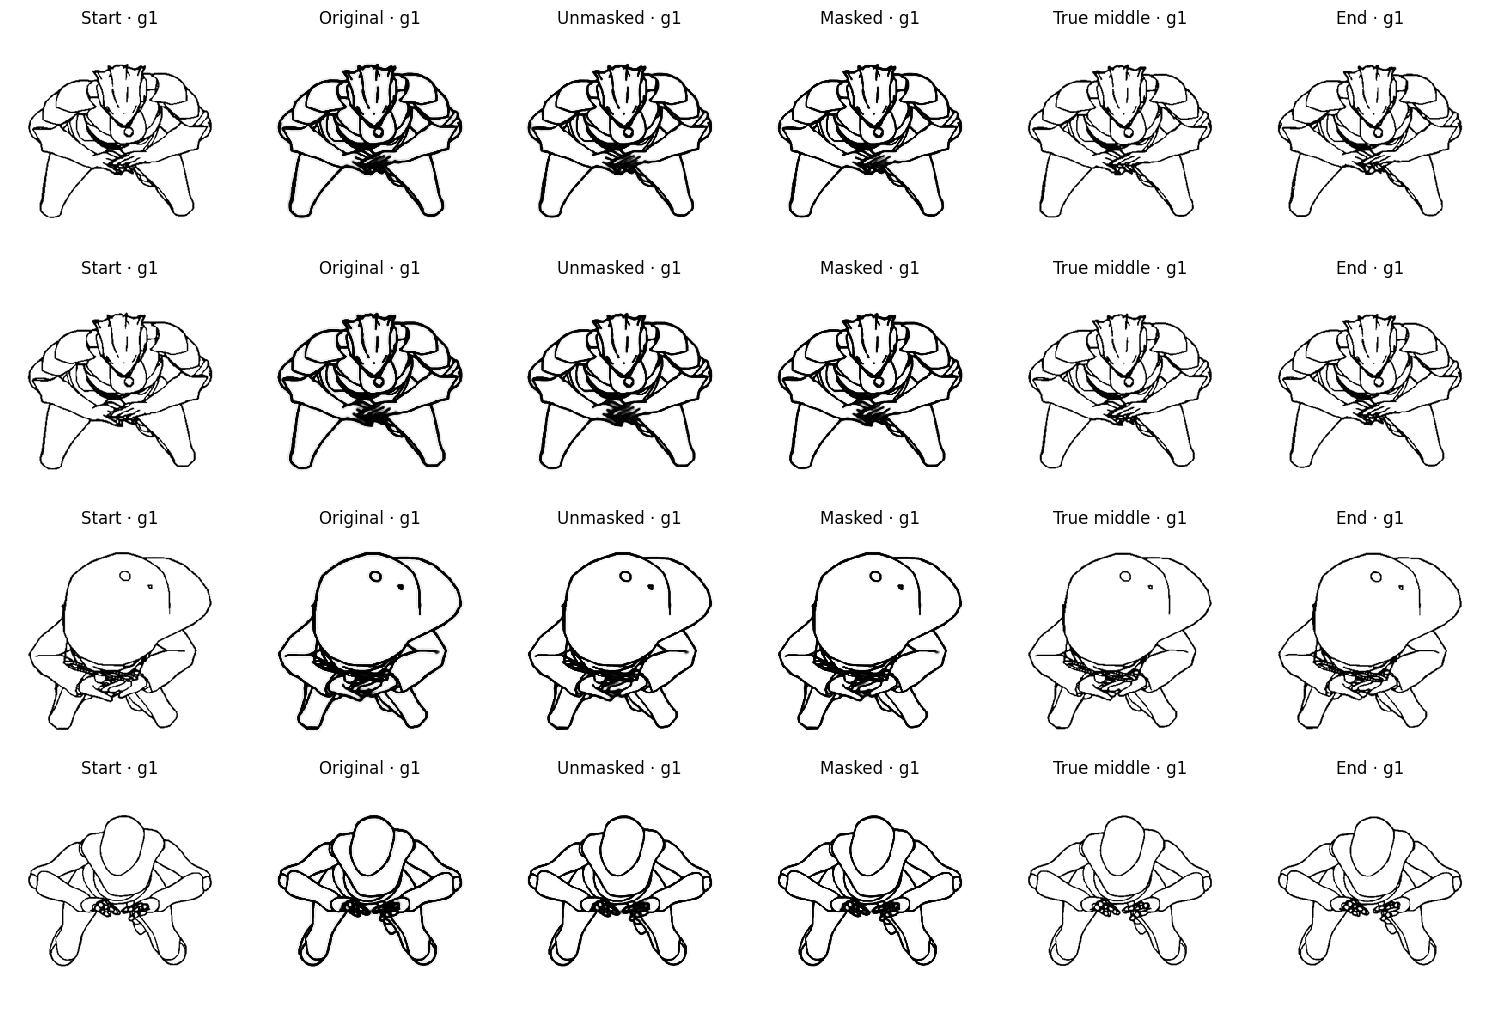

In [ ]:
# Best test examples per model
TOP_K = 4

best_query = """
    SELECT id, sequence, gap, line_f1, chamfer_px,
           1.0 * ink_fraction / target_ink_fraction AS ink_ratio
    FROM scores
    WHERE model = ? AND target_ink_fraction > 0
    ORDER BY line_f1 DESC, chamfer_px ASC, ABS(ink_ratio - 1) ASC, id
    LIMIT ?
"""

with contextlib.closing(sqlite3.connect(db_path)) as db:
    best_examples = {
        name: db.execute(best_query, (name, TOP_K)).fetchall() for name in models
    }

for name, examples in best_examples.items():
    print(f"\nBest examples for {name} (panel rows from top to bottom)")
    for rank, (key, sequence, gap, f1, chamfer, ratio) in enumerate(examples, 1):
        print(
            f"{rank}. {key} | {sequence} | gap {gap} | "
            f"F1 {f1:.4f} | Chamfer {chamfer:.3f} px | ink {ratio:.2f}×"
        )
    if examples:
        panel([row[0] for row in examples], f"best_f1_{name}.png")

## Play test animations

Choose a seed or example ID to compare the same animation across models. Three intermediate drawings require fresh RAFT motion for the two additional predictions. The later cells select high-scoring cases and check which have quarter-frame references.

corkscrew_evade_chad | gap 2 | test_983dcf9228fc8a8a9ebd_3mid_0.75_5fps.gif


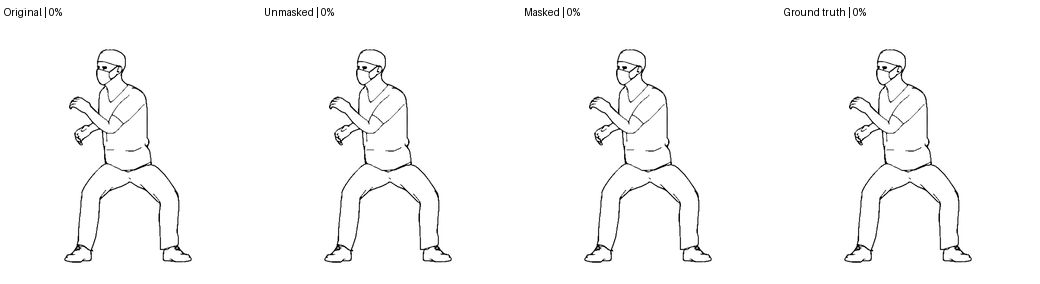

In [ ]:
def animate_test(
    gap=None, seed=42, fps=3, ink_cutoff=None, triplet_id=None, inbetweens=1
):
    import evaluation, raft_tf

    if (
        fps <= 0
        or inbetweens not in (1, 3)
        or (ink_cutoff is not None and not 0 <= ink_cutoff <= 1)
    ):
        raise ValueError(
            "Choose positive fps, 1 or 3 in-betweens, and a cutoff in [0,1] or None."
        )
    cases = (
        evaluation.recursive_cases(DATA_ROOT, "test")
        if inbetweens == 3
        else [(r, None, None) for r in rows]
    )
    cases = [
        c
        for c in cases
        if (gap is None or c[0]["gap"] == gap)
        and (triplet_id is None or c[0]["id"] == triplet_id)
    ]
    if not cases:
        raise ValueError("No matching test pair. For three in-betweens try gap=2 or 4.")
    row, q1, q3 = random.Random(seed).choice(cases)
    a, b, target, p = drawings(row)
    clips = {name: [a, mid, b] for name, mid in p.items()}
    truth = [a, target, b]
    if inbetweens == 3:
        iterations = int(
            read_json(DATA_ROOT / "config.json").get("raft_iterations", 12)
        )
        motion = raft_tf.RAFTSmallTF(
            DATA_ROOT / "raft_small_tf.npz", iterations=iterations
        )
        for name, mid in p.items():
            clips[name] = [
                a,
                learning.predict_middle(models[name], motion, a, mid),
                mid,
                learning.predict_middle(models[name], motion, mid, b),
                b,
            ]
        truth = [a, frame_cache.ink(q1), target, frame_cache.ink(q3), b]
    clips["Ground truth"] = truth
    h, w = a.shape
    frames = []
    for i in range(len(truth)):
        canvas = Image.new("RGB", ((w + 4) * len(clips), h + 28), "white")
        pen = ImageDraw.Draw(canvas)
        for j, (name, clip) in enumerate(clips.items()):
            ink = clip[i]
            if ink_cutoff is not None and name in models and 0 < i < len(truth) - 1:
                ink = (ink >= ink_cutoff).astype("float32")
            pen.text(
                (j * (w + 4) + 4, 6),
                f"{name} | {round(i * 100 / (len(truth) - 1))}%",
                fill="black",
            )
            canvas.paste(raster.ink_image(ink), (j * (w + 4), 28))
        frames.append(canvas)
    play = frames + frames[-2:0:-1]
    path = OUT / f"test_{row['id']}_{inbetweens}mid_{ink_cutoff}_{fps}fps.gif"
    play[0].save(
        path,
        save_all=True,
        append_images=play[1:],
        duration=max(10, round(1000 / fps)),
        loop=0,
    )
    print(row["sequence"], "| gap", row["gap"], "|", path.name)
    display(GIF(data=path.read_bytes(), format="gif"))


animate_test(seed=43, gap=None, fps=5, inbetweens=3, ink_cutoff=0.75)


zombie_stand_up_xbot | gap 4 | F1 1.0000 | Chamfer 0.177 px | 97fb4c90f00e38bd398f
zombie_stand_up_james | gap 4 | F1 1.0000 | Chamfer 0.198 px | cea0a79903069c660cdc
zombie_stand_up_aj | gap 4 | F1 0.9996 | Chamfer 0.306 px | cfe2fe84b905fe4f9e75
swimming_chad | gap 4 | F1 0.9996 | Chamfer 0.214 px | fe102fe4e2b12200d48f


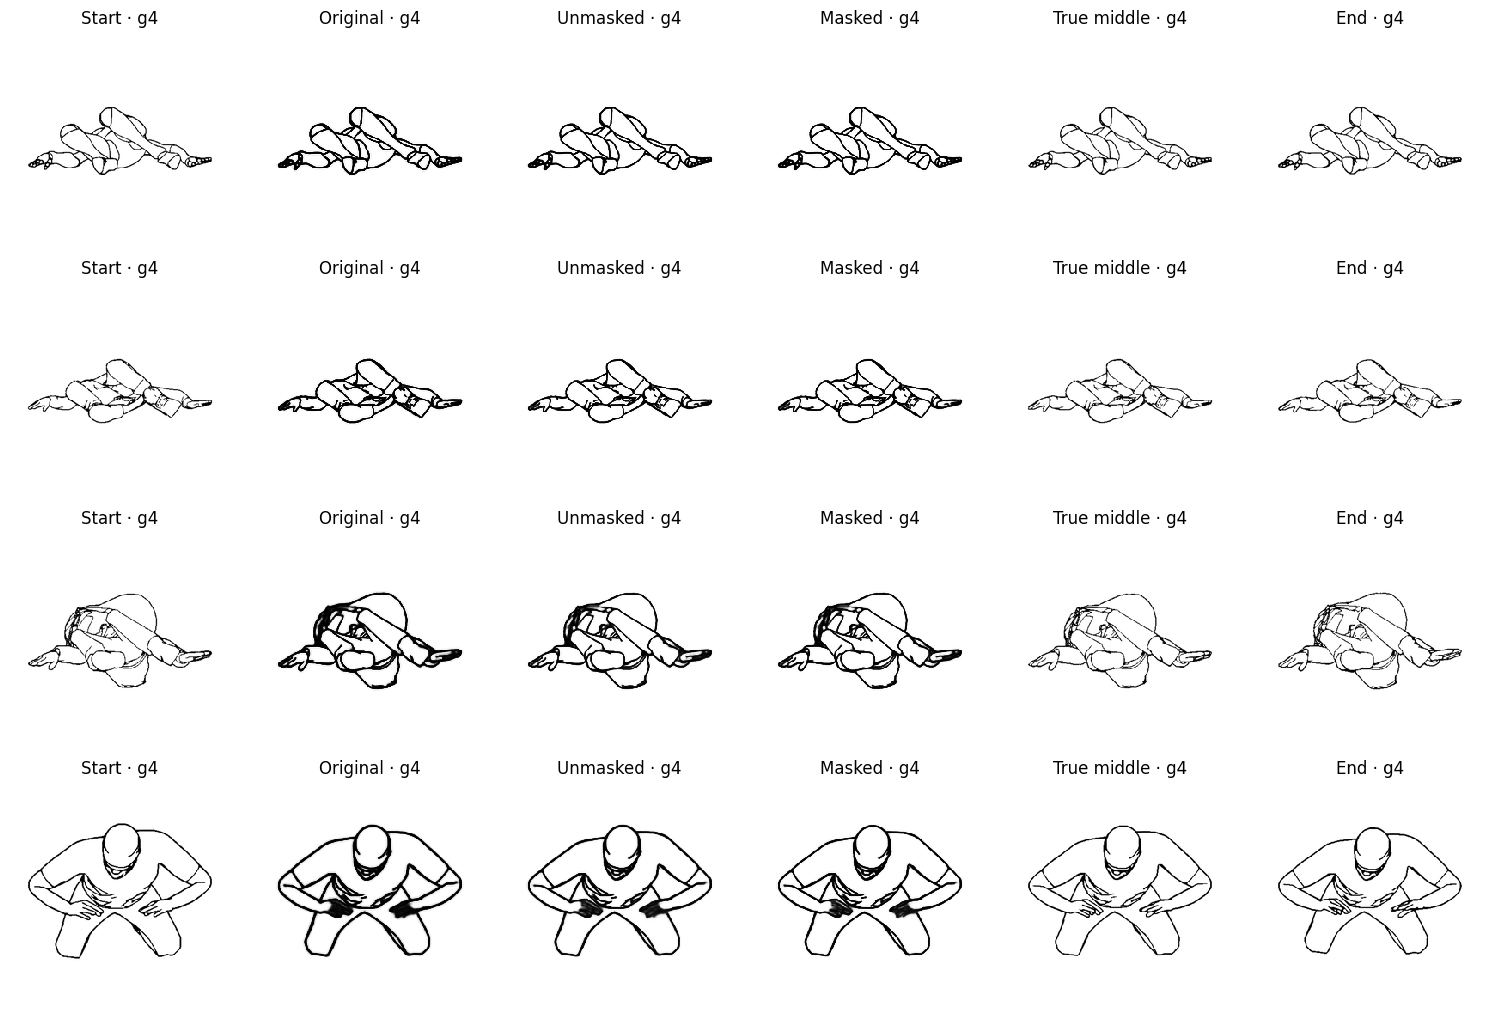

Saved: /kaggle/working/interframes_test_comparison/best_masked_gap_4.png


In [ ]:
# Change these and rerun this cell.
RANK_BY = "Masked"  # "Masked", "Unmasked", or "Original"
TOP_N = 4
GAP = 4  # None = all gaps. Use 4 to inspect larger movements.
ONE_PER_SEQUENCE = True

query = """
    SELECT id, sequence, gap, line_f1, chamfer_px
    FROM scores
    WHERE model = ?
"""
params = [RANK_BY]
if GAP is not None:
    query += " AND gap = ?"
    params.append(GAP)
query += " ORDER BY line_f1 DESC, chamfer_px ASC, id ASC"

selected = []
seen_sequences = set()

with contextlib.closing(sqlite3.connect(db_path)) as db:
    for key, sequence, gap, f1, chamfer in db.execute(query, params):
        if ONE_PER_SEQUENCE and sequence in seen_sequences:
            continue
        selected.append(key)
        seen_sequences.add(sequence)
        print(
            f"{sequence} | gap {gap} | F1 {f1:.4f} | Chamfer {chamfer:.3f} px | {key}"
        )
        if len(selected) >= TOP_N:
            break

if not selected:
    raise ValueError(f"No scored examples for model={RANK_BY!r}, gap={GAP}.")

filename = f"best_{RANK_BY.lower()}_gap_{GAP or 'all'}.png"
panel(selected, filename)
print("Saved:", OUT / filename)

In [ ]:
import evaluation

# Only these test triplets have both quarter-frame references.
eligible = {row["id"] for row, _, _ in evaluation.recursive_cases(DATA_ROOT, "test")}

with contextlib.closing(sqlite3.connect(db_path)) as db:
    ranked = db.execute(
        """SELECT id, gap, line_f1 FROM scores
           WHERE model = ?
           ORDER BY line_f1 DESC, chamfer_px ASC, id ASC""",
        (RANK_BY,),
    )
    best = next(
        (r for r in ranked if r[0] in eligible and (GAP is None or r[1] == GAP)),
        None,
    )

if best is None:
    raise ValueError(
        "No eligible example for this filter. Set GAP = None, 2, or 4 and rerun."
    )

key, gap, f1 = best
print(f"{RANK_BY} | gap {gap} | midpoint F1 {f1:.4f} | {key}")

Masked | gap 4 | midpoint F1 1.0000 | 97fb4c90f00e38bd398f


zombie_stand_up_xbot | gap 4 | test_97fb4c90f00e38bd398f_3mid_None_3fps.gif


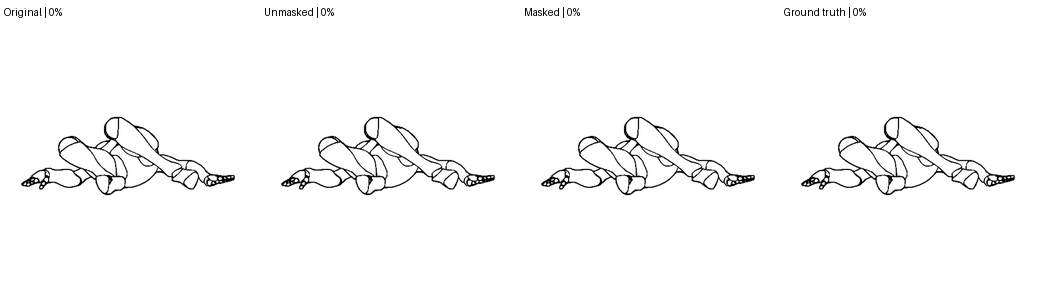

In [ ]:
animate_test(triplet_id=key, fps=3, inbetweens=3, ink_cutoff=None)

## Download the test results

Package the score files, plots, image panels, and saved animations into a ZIP.

In [ ]:
archive = shutil.make_archive(
    str(OUT.parent / "interframes_three_models_test_results"), "zip", OUT
)
print("Test results:", OUT)
display(FileLink(os.path.relpath(archive)))